# **1. Mount Google Drive and extract dataset**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os

Mounted at /content/drive


In [2]:
# Path to your uploaded archive.zip in Google Drive
zip_path = "/content/drive/MyDrive/Dataset/archive.zip"
extract_path = "/content/plant_disease_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [3]:
# Check folder structure
!ls {extract_path}
!ls {extract_path}/Train
!ls {extract_path}/Validation
!ls {extract_path}/Test

Test  Train  Validation
Train
Validation
Test


# **2. Import libraries**

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# **3. Dataset Preparation**

In [5]:
# Image size and batch
img_height, img_width = 224, 224
batch_size = 32

In [6]:
# Data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

In [7]:
# Only rescale for validation and test
val_test_datagen = ImageDataGenerator(rescale=1./255)

In [16]:
# Train data generator
train_dir = os.path.join(extract_path, "Train", "Train")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

Found 1322 images belonging to 3 classes.


In [17]:
# Validation data generator
val_dir = os.path.join(extract_path, "Validation", "Validation")
val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Found 60 images belonging to 3 classes.


In [18]:
# Test data generator
test_dir = os.path.join(extract_path, "Test", "Test")
test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Found 150 images belonging to 3 classes.


# **4. Visualize sample images**

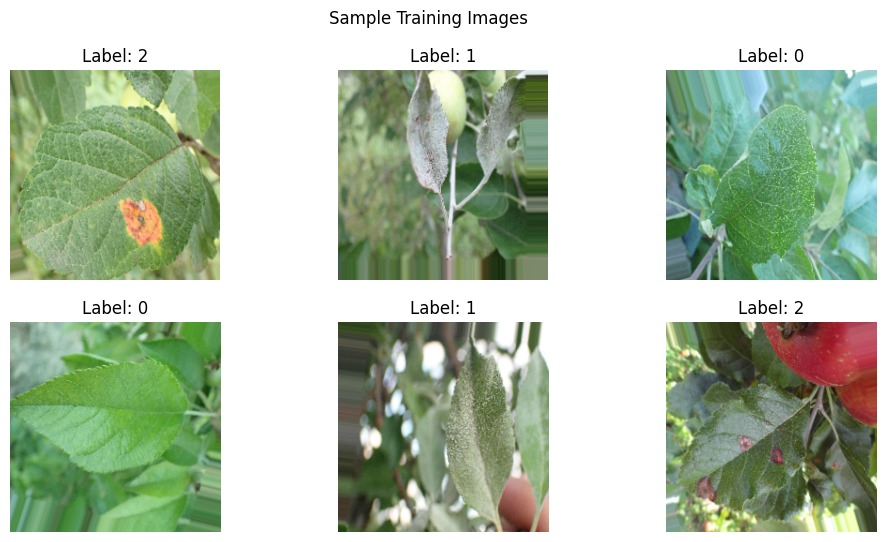

In [19]:
sample_images, sample_labels = next(train_generator)

plt.figure(figsize=(12,6))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(sample_images[i])
    plt.title(f"Label: {np.argmax(sample_labels[i])}")
    plt.axis('off')
plt.suptitle("Sample Training Images")
plt.show()

# **5. Model Architecture (Pretrained MobileNetV2)**

In [20]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False  # Freeze base layers

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(train_generator.num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# **6. Model Training**

In [21]:
epochs = 10

history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    epochs=epochs
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 168s 4s/step - accuracy: 0.4313 - loss: 1.2459 - val_accuracy: 0.7188 - val_loss: 0.7006
Epoch 2/10
 1/41 ━━━━━━━━━━━━━━━━━━━━ 1:59 3s/step - accuracy: 0.8125 - loss: 0.5880

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


41/41 ━━━━━━━━━━━━━━━━━━━━ 10s 171ms/step - accuracy: 0.8125 - loss: 0.5880 - val_accuracy: 0.7500 - val_loss: 0.6839
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 154s 4s/step - accuracy: 0.7138 - loss: 0.6626 - val_accuracy: 0.9688 - val_loss: 0.3091
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 9s 154ms/step - accuracy: 0.8125 - loss: 0.5333 - val_accuracy: 0.9688 - val_loss: 0.3115
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 202s 5s/step - accuracy: 0.8113 - loss: 0.4705 - val_accuracy: 0.9688 - val_loss: 0.2156
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 10s 178ms/step - accuracy: 0.8125 - loss: 0.4317 - val_accuracy: 0.9688 - val_loss: 0.2143
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 154s 4s/step - accuracy: 0.8844 - loss: 0.3381 - val_accuracy: 0.9375 - val_loss: 0.1872
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 7s 115ms/step - accuracy: 1.0000 - loss: 0.1431 - val_accuracy: 0.9375 - val_loss: 0.1876
Epoch 9/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 202s 5s/step - accuracy: 0.8987 - loss: 0.2797 - val_accuracy: 1.0000 - val_lo

# **7. Plot Training & Validation Accuracy**

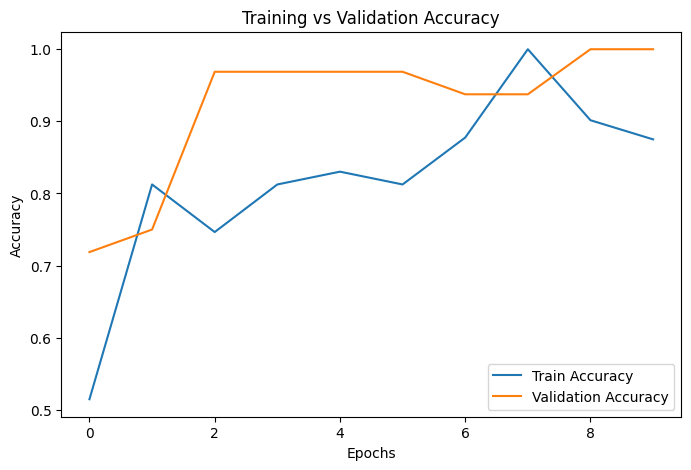

In [22]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# **8. Model Evaluation on Test Set**

5/5 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step


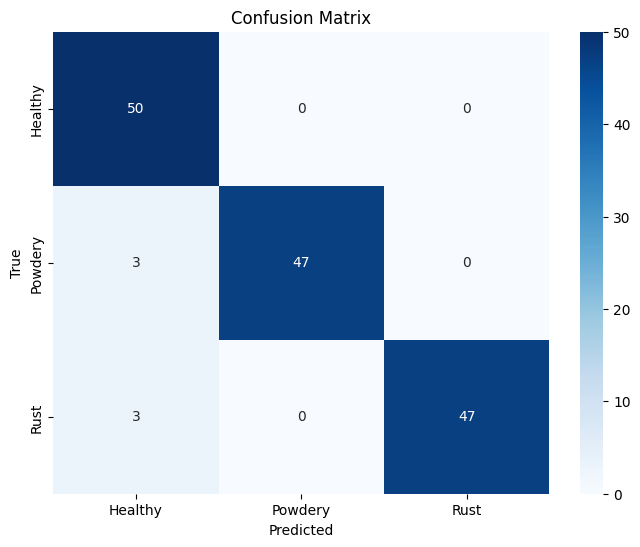

              precision    recall  f1-score   support

     Healthy       0.89      1.00      0.94        50
     Powdery       1.00      0.94      0.97        50
        Rust       1.00      0.94      0.97        50

    accuracy                           0.96       150
   macro avg       0.96      0.96      0.96       150
weighted avg       0.96      0.96      0.96       150



In [25]:
test_generator.reset()
predictions = model.predict(test_generator, steps=test_generator.samples // batch_size + 1)
predicted_classes = np.argmax(predictions, axis=1)

# True labels
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
report = classification_report(true_classes, predicted_classes, target_names=class_labels)
print(report)

# **9. Save Model**

In [26]:
model.save('/content/drive/MyDrive/plant_disease_model.h5')